## Exploratory Quality Checks
Plotting distribution across samples of:


*   Relapse vs Relapse Free status
*   ER + vs ER - Status
*   Expression Matrix Distribution
*   Present / Absent / Marginal Distribution
*   P-value of signal detection (signal vs noise detection) distribution
*   Detection rates per ProbeID (row)


### Results Review
| Check | Rationale | Result |
|-|-|-|
|Relapse vs Relapse Free| Bar chart: to see distribution, how many in each category| Unbalanced distribution|
|ER Status| Bar chart: how many ER+ how many ER-| Unbalanced distribution|
|Expression Matrix | Box Plot: visually identify general trend, outliers | Majority of signal is under 60k, with alot of outliers showing higher signal intensity than 60k|
PAM Distribution | We use this information to filter ProbeIDs with weak signals (aka ambiguous if signal or background noise). Used bar chart to get a sense of how many are marked Present Absent or Marginal | Similar amount of Present and Absent, very few marked marginal|
PAM detection rates | Get a more meaningful look at each ProbeID signal strength | U-shaped distribution, with most values either being very strong, or almost no signal at all|
P-value distribution | Heat map: visually see if probes consistently hit the threshold | There seems to be consistency across Probes, but data is too large to make meaningful decisions at this step|
P-value detection rates | Get a more meaningful look at each ProbeID signal strength | U-shaped distribution, with most values either being very strong, or almost no signal at all|

Dataset dimensions: (286, 11134)


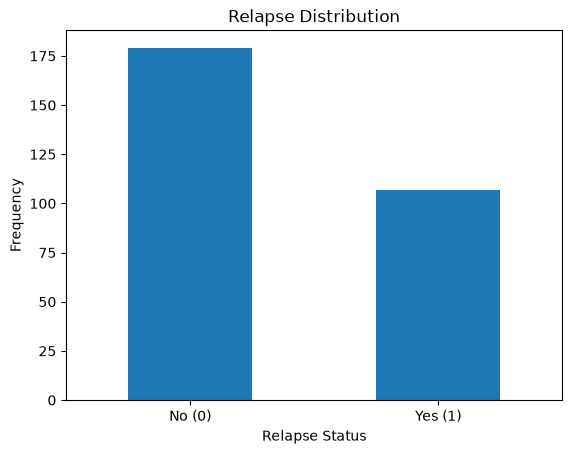

Relapse
0    179
1    107
Name: count, dtype: int64
Relapse Count Relapse
0    179
1    107
Name: count, dtype: int64
Relapse Percentage Relapse
0    62.587413
1    37.412587
Name: count, dtype: float64


In [1]:
'''Distribution of how many patients relapsed versus relapse free'''
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
full_df = pd.read_csv("../data/dashboard_dataset.csv")
relapse_counts = full_df["Relapse"].value_counts()

# Display dataset dimensions
print("Dataset dimensions:", full_df.shape)

# Preview the data
#full_df.head()

'''Plotting and customizing the look of the plot'''
relapse_counts.plot(kind='bar', rot=0)
plt.title('Relapse Distribution')
plt.xlabel('Relapse Status')
plt.ylabel('Frequency')
plt.xticks([0, 1], ['No (0)', 'Yes (1)'])
plt.show()
print (relapse_counts)

'''Showcasing the Raw values of relapse and relapse free, and % of dataset they make up'''
relapse_percentage = ((relapse_counts / len(full_df)) * 100)
print("Relapse Count", relapse_counts)
print("Relapse Percentage", relapse_percentage)

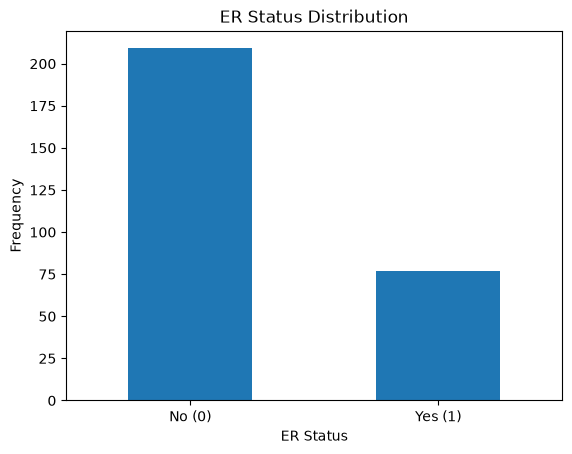

Relapse Count ER_status
ER+    209
ER-     77
Name: count, dtype: int64
Relapse Percentage ER_status
ER+    73.076923
ER-    26.923077
Name: count, dtype: float64


In [2]:
'''Distribution of ER Status'''
ER_counts = full_df['ER_status'].value_counts()

'''Plotting and customizing the look of the plot'''
ER_counts.plot(kind='bar', rot=0)
plt.title('ER Status Distribution')
plt.xlabel('ER Status')
plt.ylabel('Frequency')
plt.xticks([0, 1], ['No (0)', 'Yes (1)'])
plt.show()


'''Showcasing the Raw values of relapse and relapse free, and % of dataset they make up'''
ER_percentage = ((ER_counts / len(full_df)) * 100)
print("Relapse Count", ER_counts)
print("Relapse Percentage", ER_percentage)

#### bivariate analysis

In [3]:
#contingency table, how many ER- samples relapsed versus didn't relapse, and how many ER+ samples relapsed versus didn't relapse.
pd.crosstab(full_df['ER_status'], full_df['Relapse'])

Relapse,0,1
ER_status,,
ER+,129,80
ER-,50,27


In [4]:
#check statistical significance using chi-square
from scipy.stats import chi2_contingency
chi_table = pd.crosstab(full_df['ER_status'], full_df['Relapse'])

chi2, p_value, dof, expected = chi2_contingency(chi_table)

print ('Chi-square statistics:', round(chi2,2))
print ('P-value:', round(p_value,2))

Chi-square statistics: 0.13
P-value: 0.72


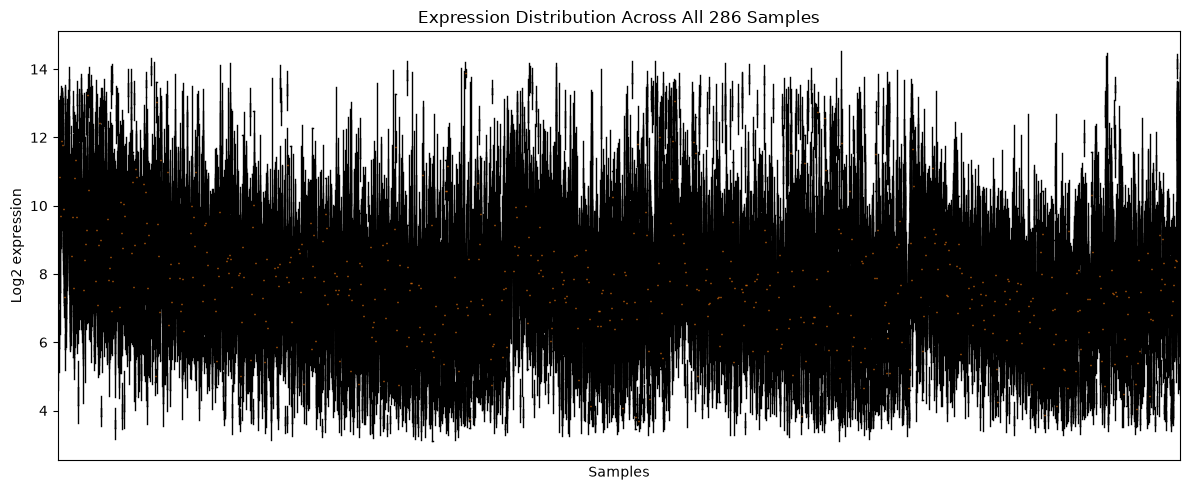

In [7]:
import matplotlib.pyplot as plt

# Remove clinical metadata and retain gene-expression measurements
expression_data = full_df.drop(
    columns=[
        "Sample_Accession",
        "Relapse",
        "ER_status",
        "Follow_up_months"
    ]
)

plt.figure(figsize=(12, 5))

plt.boxplot(
    expression_data,
    showfliers=False
)

plt.xlabel("Samples")
plt.ylabel("Log2 expression")
plt.title("Expression Distribution Across All 286 Samples")
plt.xticks([])

plt.tight_layout()
plt.show()

In [12]:
# Bivariate analysis of relapse groups
from scipy.stats import mannwhitneyu
import pandas as pd


relapse = full_df[full_df['Relapse'] == 1]
no_relapse = full_df[full_df['Relapse'] == 0]


gene_columns = full_df.select_dtypes(
    include='number'
).columns.drop('Relapse')

results = []

for gene in gene_columns:

    group1 = relapse[gene].dropna()
    group0 = no_relapse[gene].dropna()

    stat, p_value = mannwhitneyu(
        group1,
        group0,
        alternative='two-sided'
    )

    results.append({
        'Probe_ID': gene,
        'Relapse_Median': group1.median(),
        'No_Relapse_Median': group0.median(),
        'P_value': p_value
    })

results_df = pd.DataFrame(results)

print(results_df.head())

    Probe_ID  Relapse_Median  No_Relapse_Median   P_value
0  1007_s_at       10.441638          10.399324  0.549578
1    1053_at        6.316510           6.322232  0.929359
2     117_at        6.513652           6.519715  0.418126
3     121_at        8.289112           8.340852  0.397210
4    1294_at        7.941102           7.988678  0.048387


In [13]:
# FDR correction for 11 k probes

from statsmodels.stats.multitest import multipletests


results_df['FDR'] = multipletests(
    results_df['P_value'],
    method='fdr_bh'
)[1]


results_df = results_df.sort_values('FDR')


#print(results_df.head(10))

# Count probes significant after FDR correction
significant_probes = results_df[results_df['FDR'] < 0.05]

print("Total probes tested:", len(results_df))
print("Significant probes:", len(significant_probes))
print("Percentage significant:",
      round(len(significant_probes) / len(results_df) * 100, 2), "%")

Total probes tested: 11131
Significant probes: 266
Percentage significant: 2.39 %


In [15]:
from lifelines import KaplanMeierFitter
print(full_df["Relapse"].value_counts())

print("\nFollow-up summary:")
print(full_df["Follow_up_months"].describe())

Relapse
0    179
1    107
Name: count, dtype: int64

Follow-up summary:
count    286.000000
mean      77.520979
std       42.267958
min        2.000000
25%       37.000000
50%       86.000000
75%      108.000000
max      171.000000
Name: Follow_up_months, dtype: float64


In [16]:
from lifelines import KaplanMeierFitter

# Initialize the Kaplan-Meier estimator
kmf = KaplanMeierFitter()

# Fit the survival model
kmf.fit(
    durations=full_df["Follow_up_months"],
    event_observed=full_df["Relapse"],
    label="Relapse-free survival"
)

# Display survival estimates
print(kmf.survival_function_.head(10))

          Relapse-free survival
timeline                       
0.0                    1.000000
2.0                    0.996503
5.0                    0.993007
6.0                    0.986014
7.0                    0.975524
8.0                    0.968531
9.0                    0.958042
11.0                   0.944056
12.0                   0.940559
13.0                   0.937063


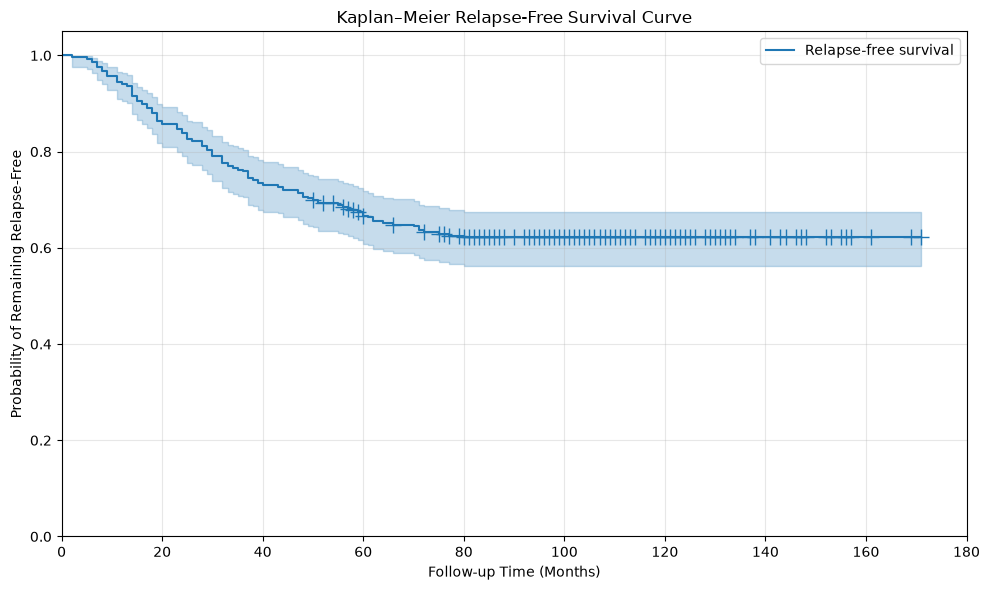

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

kmf.plot_survival_function(
    ci_show=True,
    show_censors=True
)

plt.title("Kaplan–Meier Relapse-Free Survival Curve")
plt.xlabel("Follow-up Time (Months)")
plt.ylabel("Probability of Remaining Relapse-Free")

plt.ylim(0, 1.05)
plt.xlim(0, 180)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Extract relapse-free survival estimates at selected time points
time_points = [36, 60, 84, 120]

survival_estimates = kmf.predict(time_points)

print("Relapse-Free Survival Estimates:")
print((survival_estimates * 100).round(2))

Relapse-Free Survival Estimates:
36     75.87
60     66.69
84     62.17
120    62.17
Name: Relapse-free survival, dtype: float64


## Welch's test, FDR Correction, and calculating effect size and inspecting results

In [19]:
# Separate clinical outcome from gene-expression features
X = full_df.drop(
    columns=["Sample_Accession","Relapse", "ER_status", "Follow_up_months"]
)

y = full_df["Relapse"]

print("Expression matrix:", X.shape)
print("\nRelapse groups:")
print(y.value_counts())

#comparing expressions between the two
mean_no_relapse = X[y == 0].mean()
mean_relapse = X[y == 1].mean()

mean_difference = mean_relapse - mean_no_relapse

print(mean_difference.sort_values(ascending=False).head())

print("Expression features:", X.shape[1])
print("Non-numeric columns:", X.select_dtypes(exclude="number").columns.tolist())
print("Missing values:", X.isna().sum().sum())

Expression matrix: (286, 11130)

Relapse groups:
Relapse
0    179
1    107
Name: count, dtype: int64
37892_at       0.700724
204540_at      0.687746
202620_s_at    0.596349
204475_at      0.589552
203878_s_at    0.570910
dtype: float64
Expression features: 11130
Non-numeric columns: []
Missing values: 0


In [20]:
from scipy.stats import ttest_ind

t_stats, p_values = ttest_ind(
    X[y == 1],
    X[y == 0],
    axis=0,
    equal_var=False
)

print("Number of tests:", len(p_values))
print("Smallest p-value:", p_values.min())
print("Raw p-values below 0.05:", (p_values < 0.05).sum())

# We need to implement FDR because there are alot of probes and this many will introduce alot of false positives

from statsmodels.stats.multitest import multipletests

reject, p_adjusted, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="fdr_bh"
)

print("FDR-significant probes:", reject.sum())
print("Smallest adjusted p-value:", p_adjusted.min())

Number of tests: 11130
Smallest p-value: 4.061262234730934e-09
Raw p-values below 0.05: 2057
FDR-significant probes: 249
Smallest adjusted p-value: 4.5201848672555296e-05


In [21]:
# creating a results dataframe  to make it easier to rank probes

de_results = pd.DataFrame({
    "Probe_ID": X.columns,
    "Mean_No_Relapse": mean_no_relapse.values,
    "Mean_Relapse": mean_relapse.values,
    "Mean_Difference": mean_difference.values,
    "T_Statistic": t_stats,
    "P_Value": p_values,
    "Adjusted_P_Value": p_adjusted,
    "Significant": reject
})

de_results = de_results.sort_values("Adjusted_P_Value")

print(de_results.head(10))
print("\nFDR-significant probes:", de_results["Significant"].sum())

          Probe_ID  Mean_No_Relapse  Mean_Relapse  Mean_Difference  \
1641   202324_s_at         8.492540      8.843365         0.350825   
10613  222077_s_at         6.796308      7.258862         0.462554   
5129   209380_s_at         7.714745      8.136501         0.421756   
5765   210849_s_at         8.485495      8.688922         0.203427   
825    201369_s_at         7.262710      6.767469        -0.495241   
6532     212474_at         7.717969      7.996046         0.278076   
3333     204641_at         6.865599      7.348151         0.482552   
10268    221306_at         6.644204      6.524884        -0.119319   
1885   202620_s_at         7.540189      8.136538         0.596349   
1177     201769_at         8.318151      8.525874         0.207723   

       T_Statistic       P_Value  Adjusted_P_Value  Significant  
1641      6.100365  4.061262e-09          0.000045         True  
10613     5.146727  5.665880e-07          0.003153         True  
5129      4.873072  2.308626e-0

In [22]:
print("FDR-significant probes:", de_results["Significant"].sum())

print("\nSignificant probes by direction:")
print(
    de_results.loc[de_results["Significant"], "Mean_Difference"]
    .gt(0)
    .value_counts()
)

FDR-significant probes: 249

Significant probes by direction:
Mean_Difference
True     159
False     90
Name: count, dtype: int64
